<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Auto_arima.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 10.4 MB/s eta 0:00:00
INDIA 10-YEAR GOVERNMENT BOND YIELD
FRED Series : INDIRLTLT01STM
Observations: 175
Start       : 2011-12-01 00:00:00
End         : 2026-06-01 00:00:00

First observations:


,Yield
DATE,
2011-12-01,8.5600
2012-01-01,8.2350
2012-02-01,8.1925
2012-03-01,8.3740
2012-04-01,8.5875



Last observations:


,Yield
DATE,
2026-02-01,6.77
2026-03-01,6.84
2026-04-01,7.05
2026-05-01,7.02
2026-06-01,6.89


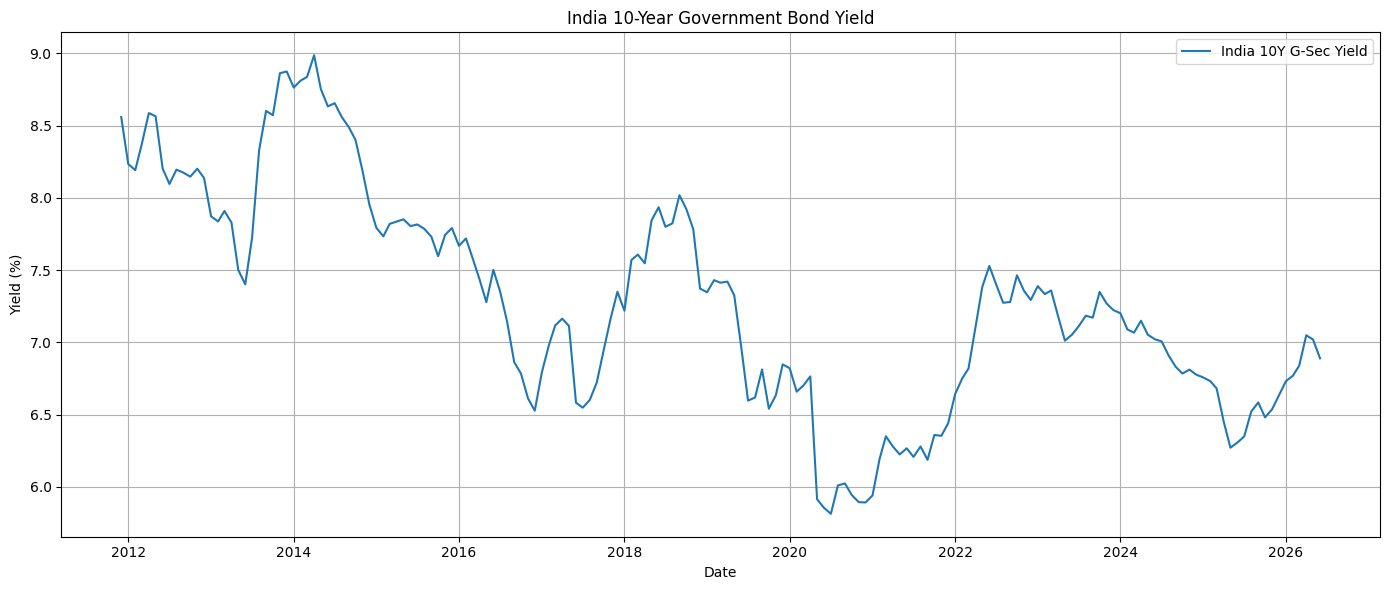


ADF TEST: YIELD LEVEL
ADF Statistic : -2.062353
P-Value       : 0.259920
Result        : Yield level is non-stationary

TRAIN / TEST SPLIT
Training observations: 140
Testing observations : 35
Training period: 2011-12-01 00:00:00 → 2023-07-01 00:00:00
Testing period : 2023-08-01 00:00:00 → 2026-06-01 00:00:00

AUTO-ARIMA MODEL SELECTION
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-73.372, Time=0.10 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-80.384, Time=0.16 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-83.031, Time=0.41 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-74.923, Time=0.10 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-81.329, Time=0.28 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=-81.453, Time=0.47 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-79.507, Time=0.29 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=-84.717, Time=0.04 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=-82.996, Time=0.07 sec
 ARIMA(0,1,2)(0,0,0)[0]          

,Forecast,Actual
2023-08-01,7.115172,7.1850
2023-09-01,7.196587,7.1720
2023-10-01,7.153742,7.3500
2023-11-01,7.402364,7.2700
2023-12-01,7.220030,7.2240
2024-01-01,7.215303,7.2025
2024-02-01,7.188582,7.0900
2024-03-01,7.048957,7.0680
2024-04-01,7.063082,7.1500
2024-05-01,7.166660,7.0540



OUT-OF-SAMPLE FORECAST PERFORMANCE
RMSE                : 0.091421
MAE                 : 0.071865
Directional Accuracy: 64.71%


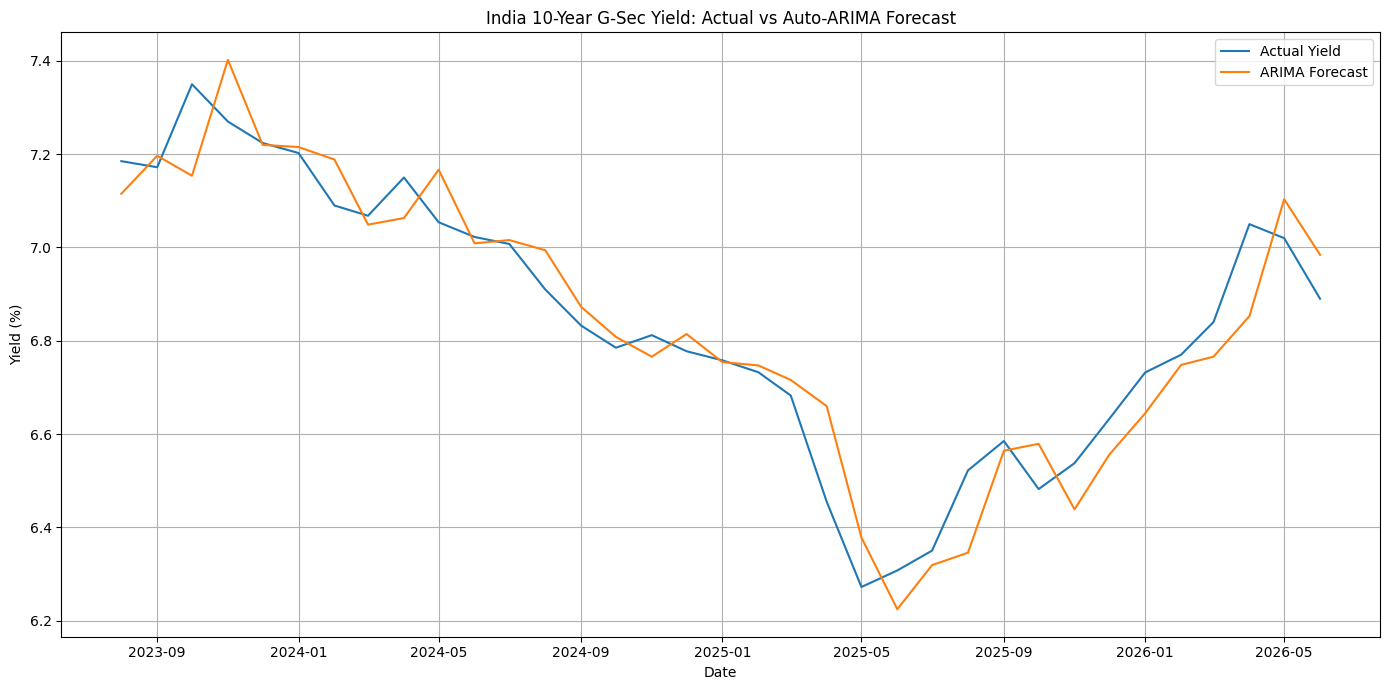

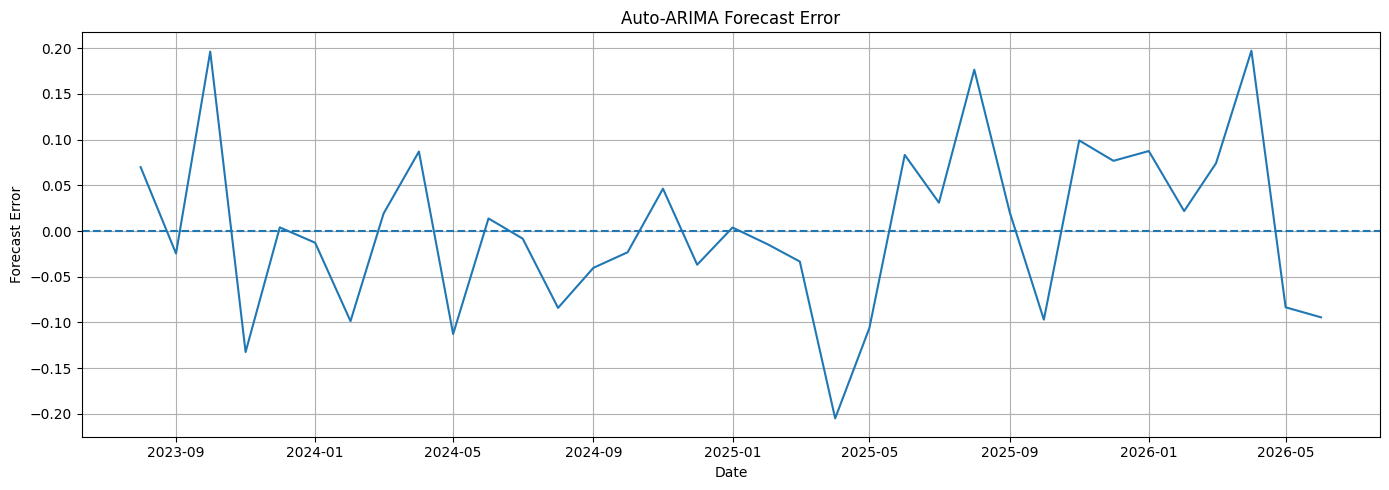


FINAL AUTO-ARIMA RESULTS
Asset                  : India 10-Year G-Sec
ARIMA Order            : (0, 1, 1)
AIC                    : -84.7168
BIC                    : -78.8478
RMSE                   : 0.091421
MAE                    : 0.071865
Directional Accuracy   : 64.71%

Files saved:
india_10y_gsec_auto_arima_backtest.csv
india_10y_gsec_auto_arima_results.csv


In [ ]:
# ============================================================
# AUTO-ARIMA FORECASTING OF INDIA 10-YEAR GOVERNMENT BOND YIELD
# ============================================================

!pip install -q pmdarima pandas_datareader

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pmdarima as pm
import pandas_datareader.data as web

from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error, mean_absolute_error


# ============================================================
# 1. DOWNLOAD DATA FROM FRED
# ============================================================

fred_series = "INDIRLTLT01STM"

data = web.DataReader(
    fred_series,
    "fred",
    start="2011-12-01",
    end="2026-06-30"
)

data = data.rename(
    columns={fred_series: "Yield"}
)

data = data.dropna()

print("=" * 70)
print("INDIA 10-YEAR GOVERNMENT BOND YIELD")
print("=" * 70)

print("FRED Series :", fred_series)
print("Observations:", len(data))
print("Start       :", data.index.min())
print("End         :", data.index.max())

print("\nFirst observations:")
display(data.head())

print("\nLast observations:")
display(data.tail())


# ============================================================
# 2. PLOT ORIGINAL SERIES
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    data.index,
    data["Yield"],
    label="India 10Y G-Sec Yield"
)

plt.title(
    "India 10-Year Government Bond Yield"
)

plt.xlabel("Date")
plt.ylabel("Yield (%)")

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 3. ADF TEST ON YIELD LEVEL
# ============================================================

adf_stat, p_value, _, _, _, _ = adfuller(
    data["Yield"]
)

print("\n" + "=" * 70)
print("ADF TEST: YIELD LEVEL")
print("=" * 70)

print(
    f"ADF Statistic : {adf_stat:.6f}"
)

print(
    f"P-Value       : {p_value:.6f}"
)

if p_value < 0.05:

    print(
        "Result        : Yield level is stationary"
    )

else:

    print(
        "Result        : Yield level is non-stationary"
    )


# ============================================================
# 4. TRAIN / TEST SPLIT
# ============================================================

split = int(
    len(data) * 0.80
)

train = data.iloc[
    :split
].copy()

test = data.iloc[
    split:
].copy()

print("\n" + "=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print(
    "Training observations:",
    len(train)
)

print(
    "Testing observations :",
    len(test)
)

print(
    "Training period:",
    train.index.min(),
    "→",
    train.index.max()
)

print(
    "Testing period :",
    test.index.min(),
    "→",
    test.index.max()
)


# ============================================================
# 5. AUTO-ARIMA
# ============================================================
#
# Automatically selects:
#
# p = AR order
# d = differencing order
# q = MA order
#
# ADF is used to help determine d.
# AIC is used for model selection.
# ============================================================

print("\n" + "=" * 70)
print("AUTO-ARIMA MODEL SELECTION")
print("=" * 70)

auto_model = pm.auto_arima(

    train["Yield"],

    seasonal=False,

    # Automatically determine differencing
    test="adf",

    # AR order search
    start_p=0,
    max_p=5,

    # MA order search
    start_q=0,
    max_q=5,

    # Maximum differencing
    max_d=2,

    # Model selection criterion
    information_criterion="aic",

    # Stepwise search
    stepwise=True,

    suppress_warnings=True,

    error_action="ignore",

    trace=True
)


# ============================================================
# 6. SELECTED ARIMA MODEL
# ============================================================

best_order = auto_model.order

print("\n" + "=" * 70)
print("SELECTED AUTO-ARIMA MODEL")
print("=" * 70)

print(
    "Selected (p,d,q):",
    best_order
)

print(
    f"AIC: {auto_model.aic():.4f}"
)

print(
    f"BIC: {auto_model.bic():.4f}"
)

print("\nModel Summary:")
print(
    auto_model.summary()
)


# ============================================================
# 7. ROLLING OUT-OF-SAMPLE FORECAST
# ============================================================
#
# At every test observation:
#
# 1. Fit using available history
# 2. Forecast one month ahead
# 3. Observe actual yield
# 4. Add actual yield to history
#
# No future information is used.
# ============================================================

print("\n" + "=" * 70)
print("ROLLING OUT-OF-SAMPLE FORECAST")
print("=" * 70)

history = list(
    train["Yield"]
)

forecasts = []
actuals = []
dates = []


for i in range(
    len(test)
):

    try:

        model = pm.ARIMA(
            order=best_order
        )

        model.fit(
            np.asarray(history)
        )

        forecast = model.predict(
            n_periods=1
        )[0]

    except Exception:

        forecast = history[-1]

    actual = (
        test["Yield"].iloc[i]
    )

    forecasts.append(
        forecast
    )

    actuals.append(
        actual
    )

    dates.append(
        test.index[i]
    )

    # Add actual observation
    history.append(
        actual
    )


# ============================================================
# 8. FORECAST DATAFRAME
# ============================================================

forecast_df = pd.DataFrame({

    "Forecast": forecasts,

    "Actual": actuals

}, index=dates)


print("\nForecast results:")
display(
    forecast_df.head(10)
)


# ============================================================
# 9. FORECAST METRICS
# ============================================================

rmse = np.sqrt(
    mean_squared_error(
        forecast_df["Actual"],
        forecast_df["Forecast"]
    )
)

mae = mean_absolute_error(
    forecast_df["Actual"],
    forecast_df["Forecast"]
)


# Directional accuracy
actual_change = (
    forecast_df["Actual"]
    .diff()
)

forecast_change = (
    forecast_df["Forecast"]
    -
    forecast_df["Actual"].shift(1)
)

directional_accuracy = (

    np.sign(actual_change)
    ==
    np.sign(forecast_change)

).iloc[1:].mean()


print("\n" + "=" * 70)
print("OUT-OF-SAMPLE FORECAST PERFORMANCE")
print("=" * 70)

print(
    f"RMSE                : {rmse:.6f}"
)

print(
    f"MAE                 : {mae:.6f}"
)

print(
    f"Directional Accuracy: "
    f"{directional_accuracy:.2%}"
)


# ============================================================
# 10. FORECAST ERROR
# ============================================================

forecast_df["Error"] = (
    forecast_df["Actual"]
    -
    forecast_df["Forecast"]
)


forecast_df["Absolute_Error"] = (
    forecast_df["Error"].abs()
)


# ============================================================
# 11. ACTUAL VS FORECAST
# ============================================================

plt.figure(
    figsize=(14, 7)
)

plt.plot(
    forecast_df.index,
    forecast_df["Actual"],
    label="Actual Yield"
)

plt.plot(
    forecast_df.index,
    forecast_df["Forecast"],
    label="ARIMA Forecast"
)

plt.title(
    "India 10-Year G-Sec Yield: Actual vs Auto-ARIMA Forecast"
)

plt.xlabel("Date")
plt.ylabel("Yield (%)")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 12. FORECAST ERROR
# ============================================================

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    forecast_df.index,
    forecast_df["Error"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Auto-ARIMA Forecast Error"
)

plt.xlabel("Date")
plt.ylabel("Forecast Error")

plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL AUTO-ARIMA RESULTS")
print("=" * 70)

print(
    "Asset                  : "
    "India 10-Year G-Sec"
)

print(
    f"ARIMA Order            : "
    f"{best_order}"
)

print(
    f"AIC                    : "
    f"{auto_model.aic():.4f}"
)

print(
    f"BIC                    : "
    f"{auto_model.bic():.4f}"
)

print(
    f"RMSE                   : "
    f"{rmse:.6f}"
)

print(
    f"MAE                    : "
    f"{mae:.6f}"
)

print(
    f"Directional Accuracy   : "
    f"{directional_accuracy:.2%}"
)


# ============================================================
# 14. SAVE RESULTS
# ============================================================

forecast_df.to_csv(
    "india_10y_gsec_auto_arima_backtest.csv"
)

results = pd.DataFrame({

    "Metric": [

        "Asset",
        "ARIMA Order",
        "AIC",
        "BIC",
        "RMSE",
        "MAE",
        "Directional Accuracy"

    ],

    "Value": [

        "India 10-Year G-Sec",
        str(best_order),
        auto_model.aic(),
        auto_model.bic(),
        rmse,
        mae,
        directional_accuracy

    ]

})

results.to_csv(
    "india_10y_gsec_auto_arima_results.csv",
    index=False
)


print("\nFiles saved:")
print(
    "india_10y_gsec_auto_arima_backtest.csv"
)

print(
    "india_10y_gsec_auto_arima_results.csv"
)


AUTO-ARIMA VS NAIVE RANDOM-WALK


,Model,RMSE,MAE,Directional Accuracy
0,Auto-ARIMA,0.091421,0.071865,0.647059
1,Naive Random Walk,0.095965,0.077243,0.000000



ARIMA IMPROVEMENT OVER NAIVE
RMSE Improvement : 4.74%
MAE Improvement  : 6.96%

Winner by RMSE: Auto-ARIMA
Winner by MAE : Auto-ARIMA


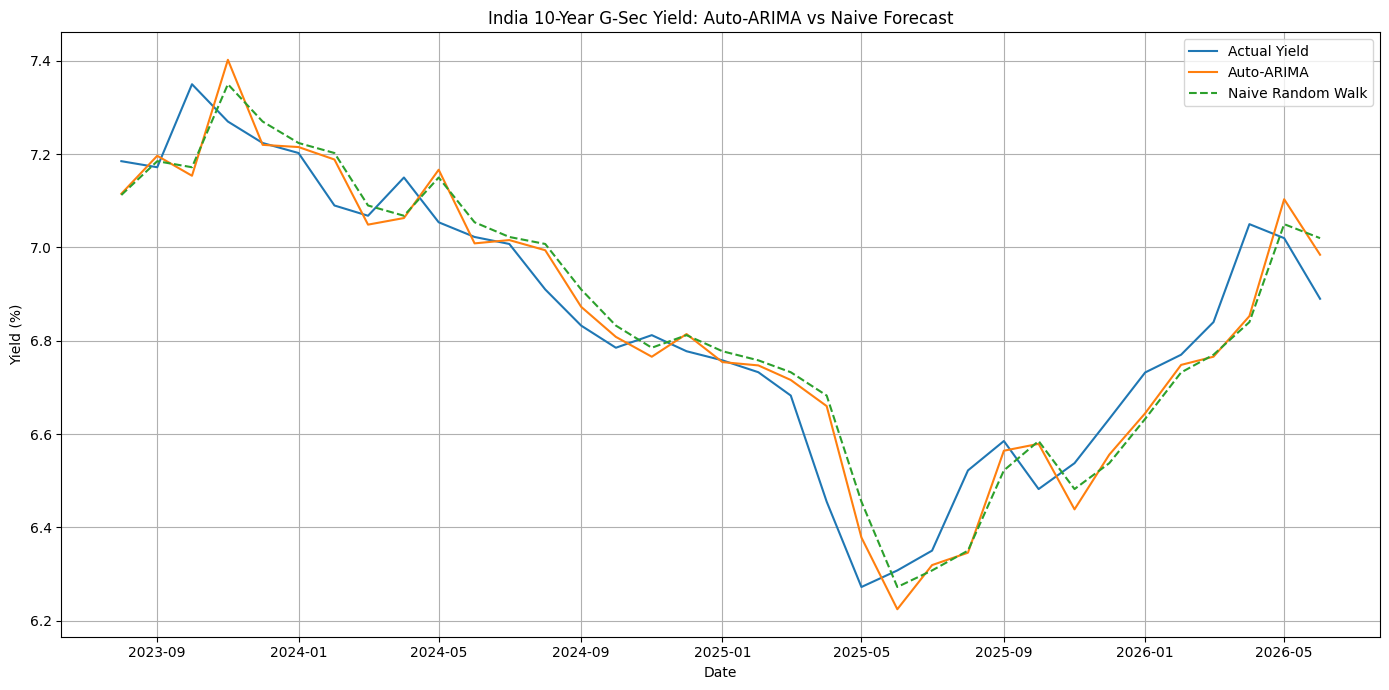


Files saved:
india_10y_gsec_arima_vs_naive.csv
india_10y_gsec_arima_complete_backtest.csv


In [ ]:
# ============================================================
# AUTO-ARIMA vs NAIVE RANDOM-WALK BENCHMARK
# INDIA 10-YEAR GOVERNMENT BOND YIELD
# ============================================================

# ------------------------------------------------------------
# 1. NAIVE FORECAST
# ------------------------------------------------------------
# Forecast for month t = actual yield from month t-1

forecast_df["Naive_Forecast"] = (
    forecast_df["Actual"].shift(1)
)

# The first test observation needs the final
# observation from the training sample
forecast_df.iloc[0, forecast_df.columns.get_loc(
    "Naive_Forecast"
)] = train["Yield"].iloc[-1]


# ------------------------------------------------------------
# 2. ARIMA ERRORS
# ------------------------------------------------------------

arima_rmse = np.sqrt(
    mean_squared_error(
        forecast_df["Actual"],
        forecast_df["Forecast"]
    )
)

arima_mae = mean_absolute_error(
    forecast_df["Actual"],
    forecast_df["Forecast"]
)


# ------------------------------------------------------------
# 3. NAIVE ERRORS
# ------------------------------------------------------------

naive_rmse = np.sqrt(
    mean_squared_error(
        forecast_df["Actual"],
        forecast_df["Naive_Forecast"]
    )
)

naive_mae = mean_absolute_error(
    forecast_df["Actual"],
    forecast_df["Naive_Forecast"]
)


# ------------------------------------------------------------
# 4. DIRECTIONAL ACCURACY
# ------------------------------------------------------------

# Actual monthly change
actual_change = (
    forecast_df["Actual"]
    -
    forecast_df["Actual"].shift(1)
)

# ARIMA predicted change
arima_change = (
    forecast_df["Forecast"]
    -
    forecast_df["Actual"].shift(1)
)

# Naive predicts zero change
naive_change = np.zeros(
    len(forecast_df)
)

valid = actual_change.notna()


arima_directional_accuracy = (

    np.sign(
        actual_change[valid]
    )
    ==
    np.sign(
        arima_change[valid]
    )

).mean()


naive_directional_accuracy = (

    np.sign(
        actual_change[valid]
    )
    ==
    np.sign(
        naive_change[valid]
    )

).mean()


# ------------------------------------------------------------
# 5. IMPROVEMENT OVER NAIVE
# ------------------------------------------------------------

rmse_improvement = (

    1
    -
    arima_rmse / naive_rmse

)

mae_improvement = (

    1
    -
    arima_mae / naive_mae

)


# ------------------------------------------------------------
# 6. COMPARISON TABLE
# ------------------------------------------------------------

comparison = pd.DataFrame({

    "Model": [

        "Auto-ARIMA",
        "Naive Random Walk"

    ],

    "RMSE": [

        arima_rmse,
        naive_rmse

    ],

    "MAE": [

        arima_mae,
        naive_mae

    ],

    "Directional Accuracy": [

        arima_directional_accuracy,
        naive_directional_accuracy

    ]

})


print("\n" + "=" * 75)
print("AUTO-ARIMA VS NAIVE RANDOM-WALK")
print("=" * 75)

display(
    comparison
)


# ------------------------------------------------------------
# 7. PRINT IMPROVEMENT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ARIMA IMPROVEMENT OVER NAIVE")
print("=" * 75)

print(
    f"RMSE Improvement : "
    f"{rmse_improvement:.2%}"
)

print(
    f"MAE Improvement  : "
    f"{mae_improvement:.2%}"
)


# ------------------------------------------------------------
# 8. BEST MODEL
# ------------------------------------------------------------

if arima_rmse < naive_rmse:

    print(
        "\nWinner by RMSE: Auto-ARIMA"
    )

else:

    print(
        "\nWinner by RMSE: Naive Random Walk"
    )


if arima_mae < naive_mae:

    print(
        "Winner by MAE : Auto-ARIMA"
    )

else:

    print(
        "Winner by MAE : Naive Random Walk"
    )


# ------------------------------------------------------------
# 9. ACTUAL VS BOTH FORECASTS
# ------------------------------------------------------------

plt.figure(
    figsize=(14, 7)
)

plt.plot(
    forecast_df.index,
    forecast_df["Actual"],
    label="Actual Yield"
)

plt.plot(
    forecast_df.index,
    forecast_df["Forecast"],
    label="Auto-ARIMA"
)

plt.plot(
    forecast_df.index,
    forecast_df["Naive_Forecast"],
    label="Naive Random Walk",
    linestyle="--"
)

plt.title(
    "India 10-Year G-Sec Yield: "
    "Auto-ARIMA vs Naive Forecast"
)

plt.xlabel("Date")
plt.ylabel("Yield (%)")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 10. SAVE COMPARISON
# ------------------------------------------------------------

comparison.to_csv(
    "india_10y_gsec_arima_vs_naive.csv",
    index=False
)

forecast_df.to_csv(
    "india_10y_gsec_arima_complete_backtest.csv"
)

print("\nFiles saved:")
print(
    "india_10y_gsec_arima_vs_naive.csv"
)

print(
    "india_10y_gsec_arima_complete_backtest.csv"
)